# DSCI 552 Homework 4
Name: Xiaoyi Kuang  
GitHub username: Xiaoyi-Kuang1

## 2. Time Series Classification

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
import statsmodels.api as sm

places = [Path('AReM'), Path('data/AReM'), Path('../AReM'), Path('../data/AReM'), Path('../../AReM'), Path('../../data/AReM')]
data_folder = None
for place in places:
    if (place / 'bending1').exists():
        data_folder = place
        break
activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
columns = ['time', 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
np.random.seed(552)
if data_folder is None:
    raise FileNotFoundError('Put the AReM folder next to this notebook or inside the data folder.')

In [2]:
def read_data(file):
    rows = []
    with open(file) as text:
        for line in text:
            line = line.strip()
            if line == '' or line.startswith('#'):
                continue
            values = line.replace(',', ' ').split()
            if len(values) == 7:
                rows.append([float(value) for value in values])
    return pd.DataFrame(rows, columns=columns)

def get_files():
    files = []
    for activity in activities:
        for number in range(1, 16):
            file = data_folder / activity / ('dataset' + str(number) + '.csv')
            if file.exists():
                files.append(file)
    return files

files = get_files()

def get_features(file, parts=1):
    data = read_data(file)
    row = {}
    for series in range(1, 7):
        values = data.iloc[:, series].to_numpy()
        pieces = np.array_split(values, parts)
        for part, piece in enumerate(pieces, start=1):
            name = str(series) + '_' + str(part)
            row['mean' + name] = np.mean(piece)
            row['std' + name] = np.std(piece, ddof=1)
            row['max' + name] = np.max(piece)
    return row

def get_rows(file_list, parts=1):
    rows = []
    for file in file_list:
        activity = file.parent.name
        label = 'bending' if activity in ['bending1', 'bending2'] else 'other'
        number = int(file.stem.replace('dataset', ''))
        if activity in ['bending1', 'bending2']:
            split = 'test' if number <= 2 else 'train'
        else:
            split = 'test' if number <= 3 else 'train'
        row = get_features(file, parts)
        row['activity'] = activity
        row['label'] = label
        row['split'] = split
        rows.append(row)
    return pd.DataFrame(rows)

frames = {}
for l in range(1, 21):
    frames[l] = get_rows(files, l)

## 2(a)(i)
Three features: mean, standard deviation and maximum.

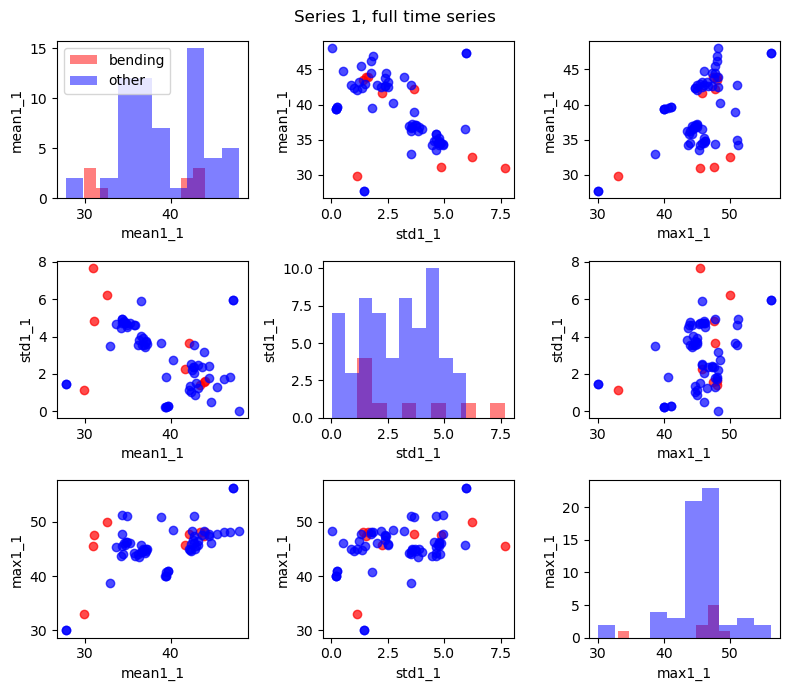

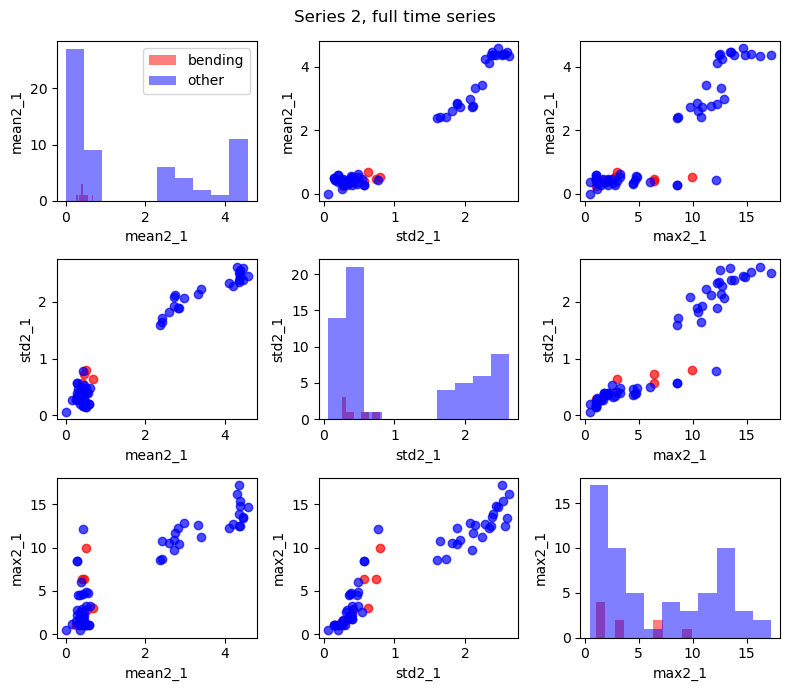

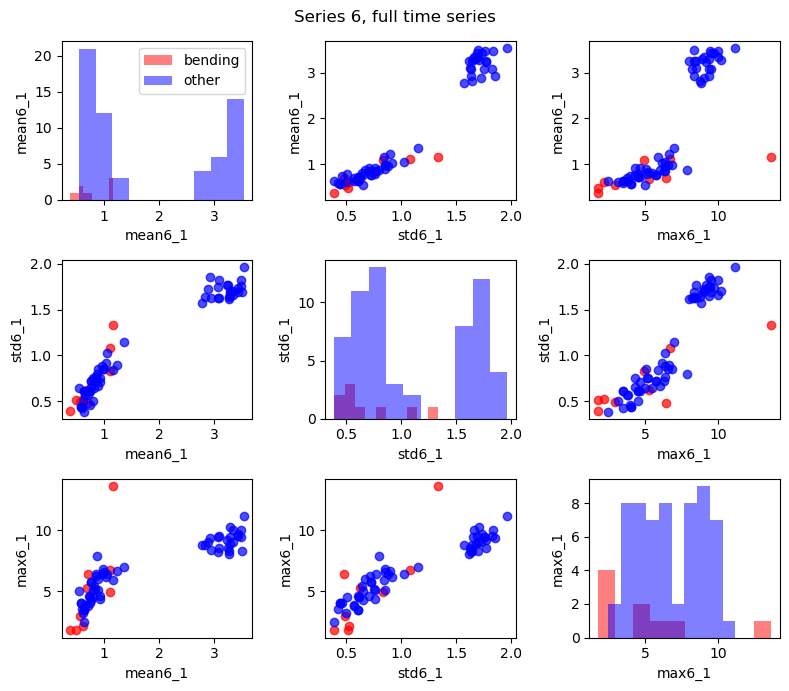

In [3]:
train_one = get_rows(files, 1).query("split == 'train'").reset_index(drop=True)

def plot_feature_grid(frame, series, part_number, title):
    suffix = str(series) + '_' + str(part_number)
    names = ['mean' + suffix, 'std' + suffix, 'max' + suffix]
    fig, axes = plt.subplots(3, 3, figsize=(8, 7))
    for row in range(3):
        for col in range(3):
            ax = axes[row, col]
            if row == col:
                for label, color in [('bending', 'red'), ('other', 'blue')]:
                    values = frame.loc[frame['label'] == label, names[row]]
                    ax.hist(values, alpha=0.5, color=color, label=label)
                if row == 0 and col == 0:
                    ax.legend()
            else:
                for label, color in [('bending', 'red'), ('other', 'blue')]:
                    part = frame[frame['label'] == label]
                    ax.scatter(part[names[col]], part[names[row]], color=color, alpha=0.7)
            ax.set_xlabel(names[col])
            ax.set_ylabel(names[row])
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

for series in [1, 2, 6]:
    plot_feature_grid(train_one, series, 1, 'Series ' + str(series) + ', full time series')

## 2(a)(ii)

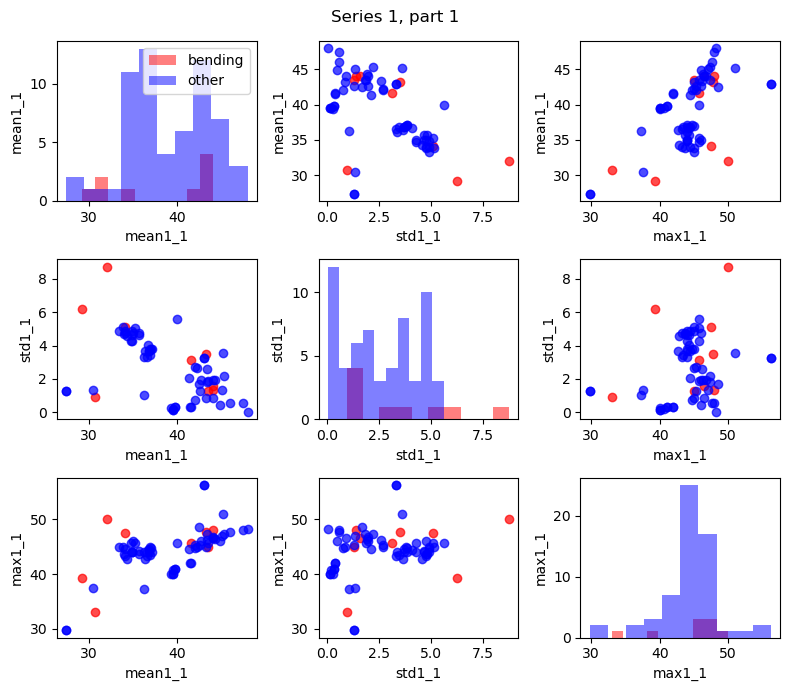

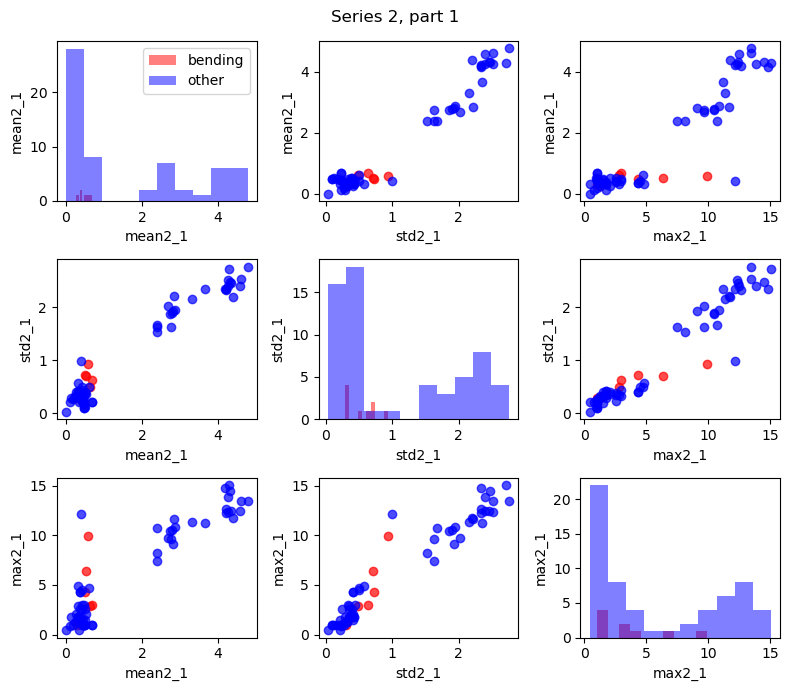

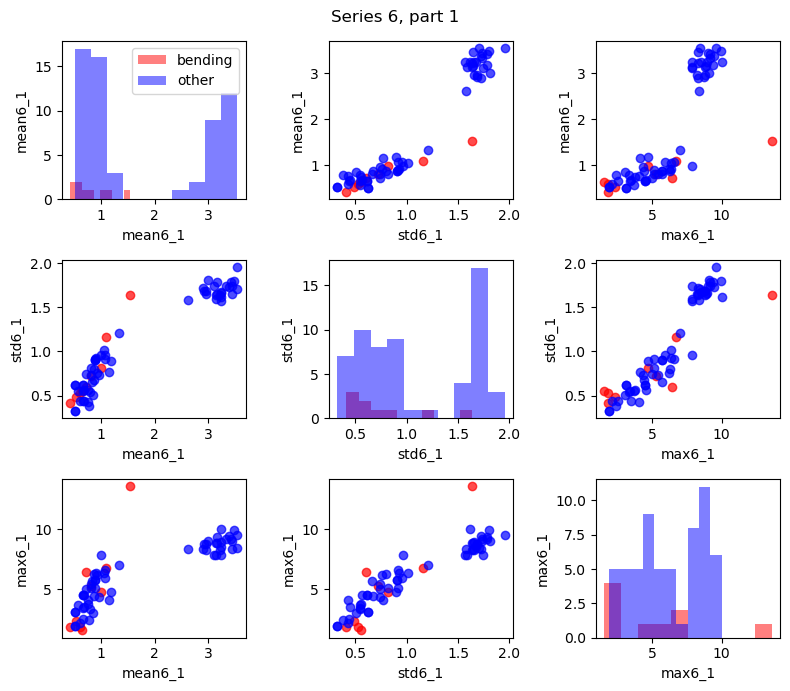

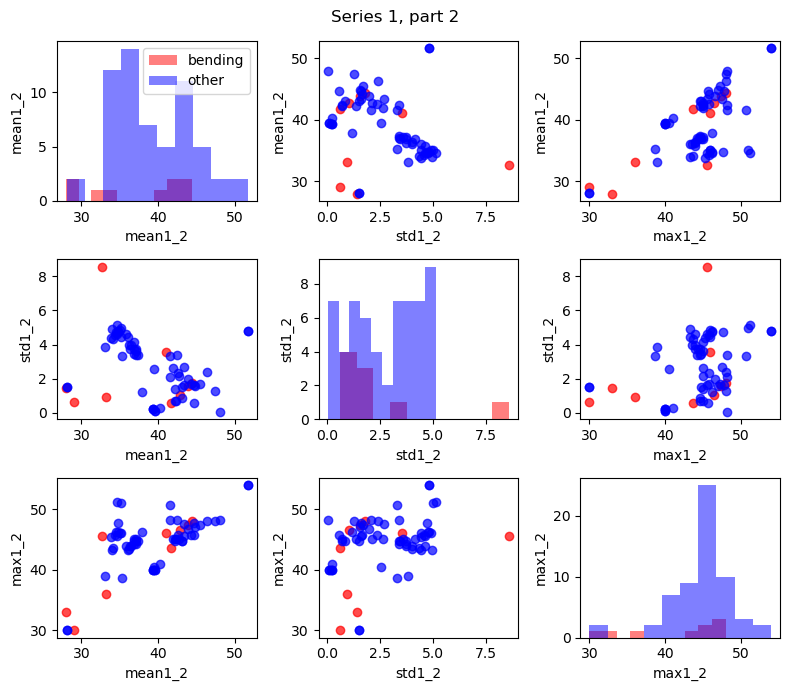

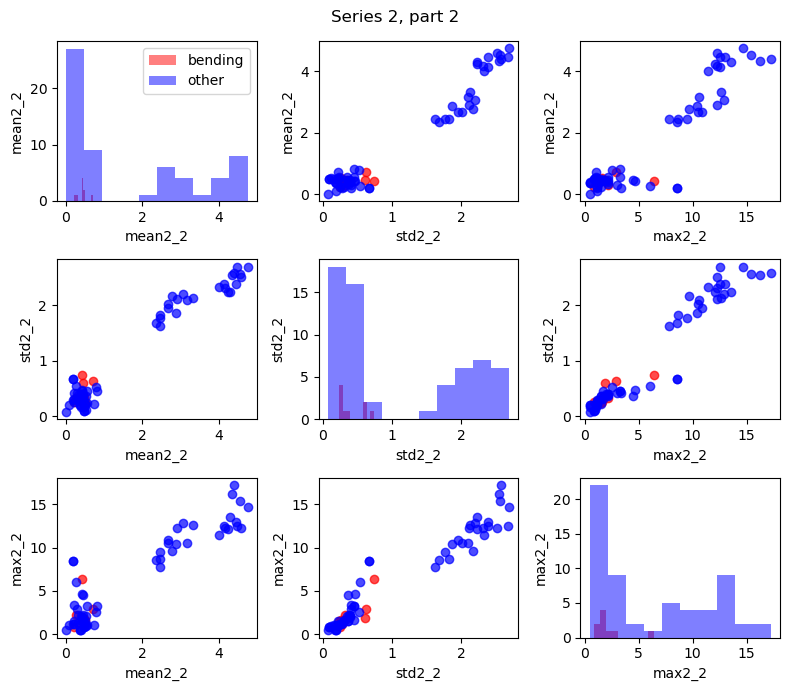

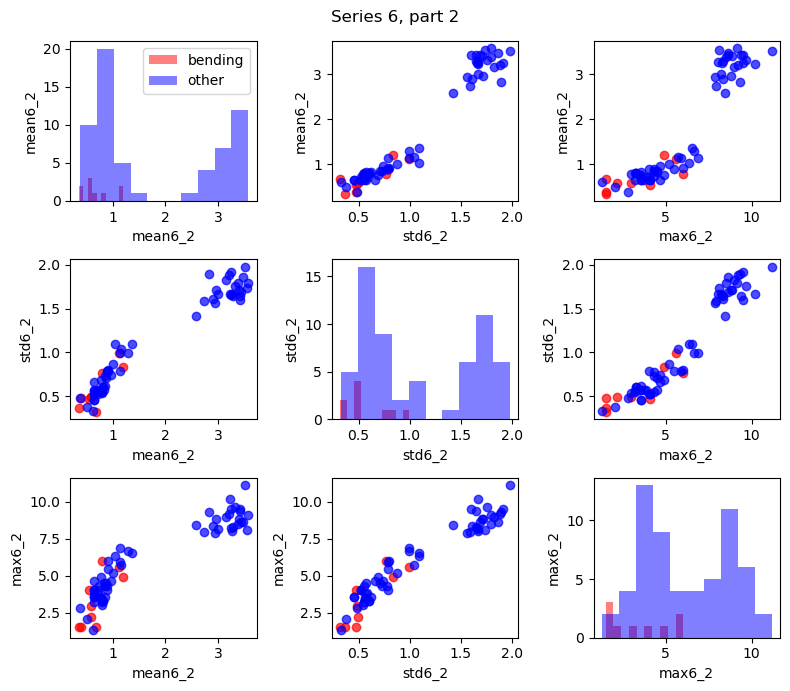

In [4]:
train_two = get_rows(files, 2).query("split == 'train'").reset_index(drop=True)

for part_number in [1, 2]:
    for series in [1, 2, 6]:
        plot_feature_grid(train_two, series, part_number, 'Series ' + str(series) + ', part ' + str(part_number))

The plots with two parts look very similar to the plots with the full series. In series 1, the bending points are mixed with the other points. In series 2 and series 6, the bending points are in the area with small values, but many other points are there too. Part 1 and part 2 show the same pattern. So cutting each series into two parts does not make a big difference for these three features.

## 2(a)(iii)
I cut each time series into l parts (l from 1 to 20) and use 5-fold stratified cross-validation to choose l and p. Stratified means that every fold has about the same share of bending instances. I need it because only 9 of the 69 training instances are bending.

**The wrong way:** First choose the best features with all the training data, then do cross-validation. The validation fold was already used to choose the features, so the score is too good.

**The right way:** In every fold, scale the data and choose p features with only the training part of that fold. Then test on the validation part of that fold. I do this with a pipeline.

For the models, I use mean, standard deviation and maximum from all six time series. I search l from 1 to 20 and the p values listed in the code. The best pair is the best result in this grid.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)

def get_matrix(frame, parts):
    names = []
    for series in range(1, 7):
        for part in range(1, parts + 1):
            suffix = str(series) + '_' + str(part)
            names.extend(['mean' + suffix, 'std' + suffix, 'max' + suffix])
    return frame[names].to_numpy(), names

def make_model(p):
    return make_pipeline(StandardScaler(), RFE(LogisticRegression(C=1e6, max_iter=5000), n_features_to_select=p, step=0.5), LogisticRegression(C=1e6, max_iter=5000))

cv_rows = []
for l in range(1, 21):
    data = frames[l].query("split == 'train'").reset_index(drop=True)
    x, names = get_matrix(data, l)
    y = (data['label'] == 'bending').astype(int).to_numpy()
    p_values = sorted(set([p for p in list(range(1, 11)) + [15, 20, 30, 40, 60, 90, 120, 180, 240, 360] if p <= x.shape[1]] + [x.shape[1]]))
    for p in p_values:
        scores = cross_val_score(make_model(p), x, y, cv=cv, scoring='accuracy')
        cv_rows.append({'l': l, 'p': p, 'cv_accuracy': scores.mean(), 'cv_sd': scores.std()})

cv_table = pd.DataFrame(cv_rows).sort_values(['cv_accuracy', 'l', 'p'], ascending=[False, True, True])
display(cv_table.head(10))
best_l = int(cv_table.iloc[0]['l'])
best_p = int(cv_table.iloc[0]['p'])
best_cv = float(cv_table.iloc[0]['cv_accuracy'])
print('Accuracy when always predicting other:', round(1 - y.mean(), 3))
print('Best l:', best_l)
print('Best p:', best_p)
print('Best cross-validation accuracy:', round(best_cv, 3))

,l,p,cv_accuracy,cv_sd
26,3,1,0.985714,0.028571
191,12,15,0.985714,0.028571
2,1,3,0.971429,0.034993
3,1,4,0.971429,0.034993
81,6,9,0.971429,0.057143
82,6,10,0.971429,0.057143
192,12,20,0.971429,0.034993
193,12,30,0.971429,0.034993
309,18,15,0.971429,0.034993
0,1,1,0.957143,0.034993


Accuracy when always predicting other: 0.87
Best l: 3
Best p: 1
Best cross-validation accuracy: 0.986


## 2(a)(iv)

Selected features: ['max5_1']
Logistic regression betas (the features are standardized):


,feature,beta
0,intercept,-4.645969
1,max5_1,4.586192


Training confusion matrix:


,Predicted other,Predicted bending
True other,60,0
True bending,1,8


Training accuracy: 0.986
Training AUC: 0.975


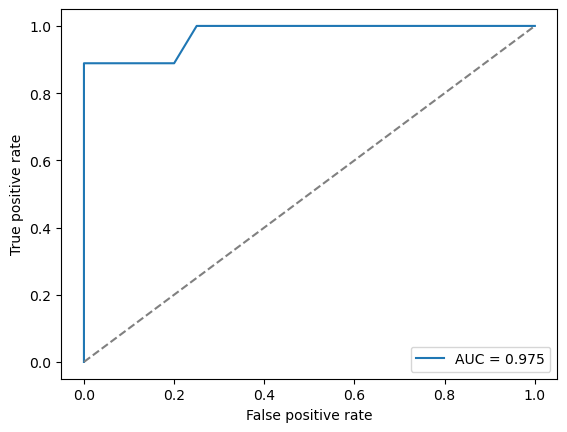

Unpenalized statsmodels estimates and p-values:


,feature,beta,p_value
0,intercept,-4.645963,0.000713
1,max5_1,4.586204,0.005198


In [6]:
train_best = get_rows(files, best_l).query("split == 'train'").reset_index(drop=True)
x_best, best_names = get_matrix(train_best, best_l)
y_best = (train_best['label'] == 'bending').astype(int).to_numpy()

best_model = make_model(best_p)
best_model.fit(x_best, y_best)
scale = best_model[0]
rfe = best_model[1]
final_model = best_model[2]

x_selected = rfe.transform(scale.transform(x_best))
selected_names = np.array(best_names)[rfe.support_]
train_prob = final_model.predict_proba(x_selected)[:, 1]
train_pred = (train_prob >= 0.5).astype(int)

print('Selected features:', selected_names.tolist())
print('Logistic regression betas (the features are standardized):')
display(pd.DataFrame({'feature': ['intercept'] + selected_names.tolist(), 'beta': [final_model.intercept_[0]] + final_model.coef_[0].tolist()}))

print('Training confusion matrix:')
display(pd.DataFrame(confusion_matrix(y_best, train_pred), index=['True other', 'True bending'], columns=['Predicted other', 'Predicted bending']))
print('Training accuracy:', round(accuracy_score(y_best, train_pred), 3))
print('Training AUC:', round(roc_auc_score(y_best, train_prob), 3))
fpr, tpr, _ = roc_curve(y_best, train_prob)
plt.plot(fpr, tpr, label='AUC = ' + str(round(roc_auc_score(y_best, train_prob), 3)))
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend()
plt.show()


if train_pred.tolist() == y_best.tolist():
    print('The training classes are separated. Finite unpenalized estimates and reliable p-values are not available.')
else:
    try:
        stats_model = sm.Logit(y_best, sm.add_constant(x_selected)).fit(disp=False, maxiter=1000)
        if stats_model.mle_retvals['converged'] and np.isfinite(stats_model.pvalues).all():
            print('Unpenalized statsmodels estimates and p-values:')
            display(pd.DataFrame({'feature': ['intercept'] + selected_names.tolist(), 'beta': stats_model.params, 'p_value': stats_model.pvalues}))
        else:
            print('The unpenalized fit did not give reliable p-values.')
    except Exception as error:
        print('The unpenalized fit could not calculate p-values:', str(error))


The first table uses sklearn with C = 1e6. The second table gives the unpenalized coefficients and p-values from statsmodels for the same selected feature.

## 2(a)(v)

In [7]:
test_best = get_rows(files, best_l).query("split == 'test'").reset_index(drop=True)
x_test, test_names = get_matrix(test_best, best_l)
x_test_selected = rfe.transform(scale.transform(x_test))
y_test = (test_best['label'] == 'bending').astype(int).to_numpy()
test_prob = final_model.predict_proba(x_test_selected)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)
test_accuracy = accuracy_score(y_test, test_pred)

print('Test confusion matrix:')
display(pd.DataFrame(confusion_matrix(y_test, test_pred), index=['True other', 'True bending'], columns=['Predicted other', 'Predicted bending']))
print('Test accuracy:', round(test_accuracy, 3))
print('Cross-validation accuracy:', round(best_cv, 3))
print('Test AUC:', round(roc_auc_score(y_test, test_prob), 3))
if test_accuracy < best_cv:
    print('The test accuracy is lower than the cross-validation accuracy.')
else:
    print('The test accuracy is not lower than the cross-validation accuracy.')

print('Class counts in training:')
print(train_best['label'].value_counts())
print('Class counts in test:')
print(test_best['label'].value_counts())

Test confusion matrix:


,Predicted other,Predicted bending
True other,15,0
True bending,2,2


Test accuracy: 0.895
Cross-validation accuracy: 0.986
Test AUC: 0.85
The test accuracy is lower than the cross-validation accuracy.
Class counts in training:
other      60
bending     9
Name: label, dtype: int64
Class counts in test:
other      15
bending     4
Name: label, dtype: int64


The test set has only 19 instances, so one mistake changes the accuracy by about 0.053. Also, choosing the best pair from many cross-validation results can make the selected score optimistic.

## 2(a)(vi)
The selected model has one training mistake. Statsmodels gives finite coefficients and p-values. I do not see complete separation in this selected model.

## 2(a)(vii)
Yes. The training set has 60 other instances and 9 bending instances. I use all 9 bending instances and randomly choose 9 other instances. I add log(9/60) to the fitted intercept to adjust for the different class proportions.

Case-control training confusion matrix:


,Predicted other,Predicted bending
True other,60,0
True bending,1,8


Case-control training AUC: 0.975
Case-control test confusion matrix:


,Predicted other,Predicted bending
True other,15,0
True bending,1,3


Case-control test AUC: 0.85


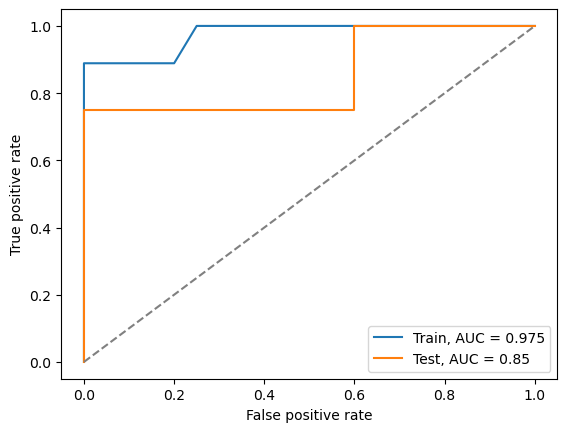

In [8]:
rng = np.random.RandomState(552)
bending_index = np.where(y_best == 1)[0]
other_index = np.where(y_best == 0)[0]
chosen_other = rng.choice(other_index, size=len(bending_index), replace=False)
chosen = np.concatenate([bending_index, chosen_other])

case_model = LogisticRegression(C=1e6, max_iter=1000)
case_model.fit(x_selected[chosen], y_best[chosen])
case_model.intercept_ = case_model.intercept_ + np.log(y_best.mean() / (1 - y_best.mean()))

case_train_prob = case_model.predict_proba(x_selected)[:, 1]
case_train_pred = (case_train_prob >= 0.5).astype(int)
case_test_prob = case_model.predict_proba(x_test_selected)[:, 1]
case_test_pred = (case_test_prob >= 0.5).astype(int)

print('Case-control training confusion matrix:')
display(pd.DataFrame(confusion_matrix(y_best, case_train_pred), index=['True other', 'True bending'], columns=['Predicted other', 'Predicted bending']))
print('Case-control training AUC:', round(roc_auc_score(y_best, case_train_prob), 3))
print('Case-control test confusion matrix:')
display(pd.DataFrame(confusion_matrix(y_test, case_test_pred), index=['True other', 'True bending'], columns=['Predicted other', 'Predicted bending']))
print('Case-control test AUC:', round(roc_auc_score(y_test, case_test_prob), 3))

fpr, tpr, _ = roc_curve(y_best, case_train_prob)
plt.plot(fpr, tpr, label='Train, AUC = ' + str(round(roc_auc_score(y_best, case_train_prob), 3)))
fpr, tpr, _ = roc_curve(y_test, case_test_prob)
plt.plot(fpr, tpr, label='Test, AUC = ' + str(round(roc_auc_score(y_test, case_test_prob), 3)))
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend()
plt.show()

## 2(b)(i)

In [9]:
c_values = [0.01, 0.1, 1, 10]
l1_rows = []
for l in range(1, 21):
    data = frames[l].query("split == 'train'").reset_index(drop=True)
    x, names = get_matrix(data, l)
    y = (data['label'] == 'bending').astype(int).to_numpy()
    for c in c_values:
        model = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='liblinear', C=c, max_iter=2000))
        scores = cross_val_score(model, x, y, cv=cv, scoring='accuracy')
        l1_rows.append({'l': l, 'C': c, 'cv_accuracy': scores.mean(), 'cv_sd': scores.std()})
l1_table = pd.DataFrame(l1_rows).sort_values(['cv_accuracy', 'l', 'C'], ascending=[False, True, True])
display(l1_table.head(10))
best_l1_l = int(l1_table.iloc[0]['l'])
best_c = float(l1_table.iloc[0]['C'])
best_l1_cv = float(l1_table.iloc[0]['cv_accuracy'])
print('Best l:', best_l1_l)
print('Best C:', best_c)
print('Best L1 cross-validation accuracy:', round(best_l1_cv, 3))

l1_train = get_rows(files, best_l1_l).query("split == 'train'").reset_index(drop=True)
x_l1, l1_names = get_matrix(l1_train, best_l1_l)
y_l1 = (l1_train['label'] == 'bending').astype(int).to_numpy()
l1_model = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='liblinear', C=best_c, max_iter=2000))
l1_model.fit(x_l1, y_l1)
print('Non-zero features:', int(np.sum(l1_model[-1].coef_ != 0)))
print('RFE cross-validation accuracy:', round(best_cv, 3))
print('L1 cross-validation accuracy:', round(best_l1_cv, 3))
if best_l1_cv > best_cv:
    print('L1 has the higher cross-validation accuracy in this search.')
elif best_l1_cv < best_cv:
    print('RFE has the higher cross-validation accuracy in this search.')
else:
    print('The two methods have the same cross-validation accuracy.')

,l,C,cv_accuracy,cv_sd
46,12,1.0,0.985714,0.028571
75,19,10.0,0.985714,0.028571
42,11,1.0,0.971429,0.034993
47,12,10.0,0.971429,0.034993
70,18,1.0,0.971429,0.034993
71,18,10.0,0.971429,0.034993
74,19,1.0,0.971429,0.034993
78,20,1.0,0.971429,0.034993
79,20,10.0,0.971429,0.034993
2,1,1.0,0.957143,0.034993


Best l: 12
Best C: 1.0
Best L1 cross-validation accuracy: 0.986
Non-zero features: 5
RFE cross-validation accuracy: 0.986
L1 cross-validation accuracy: 0.986
The two methods have the same cross-validation accuracy.


## 2(b)(ii)
I use RFE, which is the alternative allowed in 2(a)(iii). RFE removes features based on the fitted coefficients, not p-values. Both methods have a best cross-validation accuracy of about 0.986 in this search. L1 is simpler here because the penalty also selects features.

## 2(c)(i)
I choose l and C again with cross-validation, because the best values for bending against other may not be the best values for seven activities. The smallest class (bending2) has only 4 training instances, so I use 4 folds.

In [10]:
multi_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=552)
multi_rows = []
for l in range(1, 21):
    data = frames[l].query("split == 'train'").reset_index(drop=True)
    x, names = get_matrix(data, l)
    y = data['activity'].to_numpy()
    for c in c_values:
        model = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='saga', C=c, max_iter=50000, random_state=552))
        scores = cross_val_score(model, x, y, cv=multi_cv, scoring='accuracy')
        multi_rows.append({'l': l, 'C': c, 'cv_accuracy': scores.mean()})
multi_table = pd.DataFrame(multi_rows).sort_values(['cv_accuracy', 'l', 'C'], ascending=[False, True, True])
display(multi_table.head(10))
best_multi_l = int(multi_table.iloc[0]['l'])
best_multi_c = float(multi_table.iloc[0]['C'])
print('Best l:', best_multi_l)
print('Best C:', best_multi_c)

,l,C,cv_accuracy
7,2,10.0,0.899510
2,1,1.0,0.899510
6,2,1.0,0.884804
3,1,10.0,0.884804
15,4,10.0,0.883170
11,3,10.0,0.868464
59,15,10.0,0.855392
62,16,1.0,0.855392
19,5,10.0,0.853758
10,3,1.0,0.839869


Best l: 2
Best C: 10.0


Answer for 2(c)(i): I choose l = 2 and C = 10.0 with 4-fold cross-validation.
The test error of the L1-penalized multinomial logistic regression is 0.158 (3 of the 19 test instances are wrong).
Confusion matrix (rows are true activities):


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,1,0,0,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,0,0,0,0,1,2,0
standing,0,0,0,0,0,3,0
walking,0,0,0,0,0,0,3


Multiclass macro AUC: 0.95


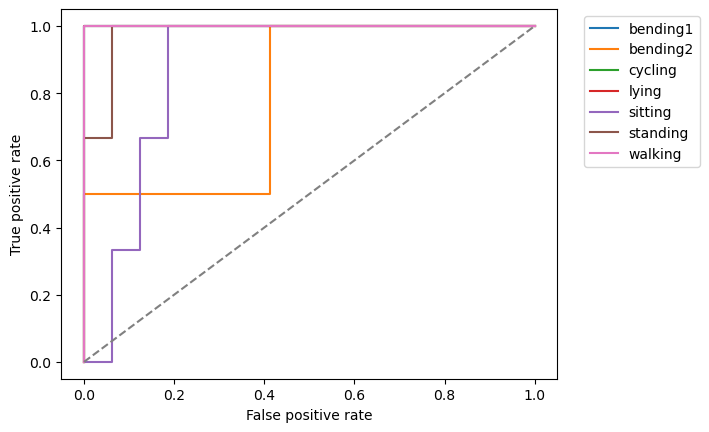

In [11]:
mult_train = get_rows(files, best_multi_l).query("split == 'train'").reset_index(drop=True)
mult_test = get_rows(files, best_multi_l).query("split == 'test'").reset_index(drop=True)
x_mult, mult_names = get_matrix(mult_train, best_multi_l)
x_mult_test, _ = get_matrix(mult_test, best_multi_l)
y_mult = mult_train['activity'].to_numpy()
y_mult_test = mult_test['activity'].to_numpy()

mult_log = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='saga', C=best_multi_c, max_iter=50000, random_state=552))
mult_log.fit(x_mult, y_mult)
mult_pred = mult_log.predict(x_mult_test)
mult_prob = mult_log.predict_proba(x_mult_test)
wrong = int(np.sum(mult_pred != y_mult_test))
print('Answer for 2(c)(i): I choose l =', best_multi_l, 'and C =', best_multi_c, 'with 4-fold cross-validation.')
print('The test error of the L1-penalized multinomial logistic regression is', round(1 - accuracy_score(y_mult_test, mult_pred), 3), '(' + str(wrong), 'of the', len(y_mult_test), 'test instances are wrong).')
print('Confusion matrix (rows are true activities):')
display(pd.DataFrame(confusion_matrix(y_mult_test, mult_pred, labels=activities), index=activities, columns=activities))

classes = mult_log.classes_
y_binary = label_binarize(y_mult_test, classes=classes)
print('Multiclass macro AUC:', round(roc_auc_score(y_binary, mult_prob, average='macro', multi_class='ovr'), 3))
for i, activity in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_binary[:, i], mult_prob[:, i])
    plt.plot(fpr, tpr, label=activity)
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend(bbox_to_anchor=(1.04, 1), loc='upper left')
plt.show()

For the multiclass problem, the confusion matrix has one row for each true activity and one column for each predicted activity. For the ROC curve, I use one activity against all the other activities and draw one curve for each activity. The macro AUC is the average of the seven AUC values.

## 2(c)(ii)
I choose l separately for Gaussian and Multinomial Naive Bayes using the same 4-fold stratified cross-validation. For Multinomial Naive Bayes, I fit MinMaxScaler inside each training fold. I use clip=True so the validation and test values stay between 0 and 1.

,model,l,cv_accuracy
0,Gaussian,1,0.913399
12,Gaussian,7,0.884804
2,Gaussian,2,0.884804
8,Gaussian,5,0.884804
4,Gaussian,3,0.870915


Gaussian Naive Bayes best l: 1
Cross-validation accuracy: 0.913
Test error: 0.105
Confusion matrix (rows are true activities):


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,1,0,0,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,0,0,0,0,3,0,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


Macro AUC: 0.997


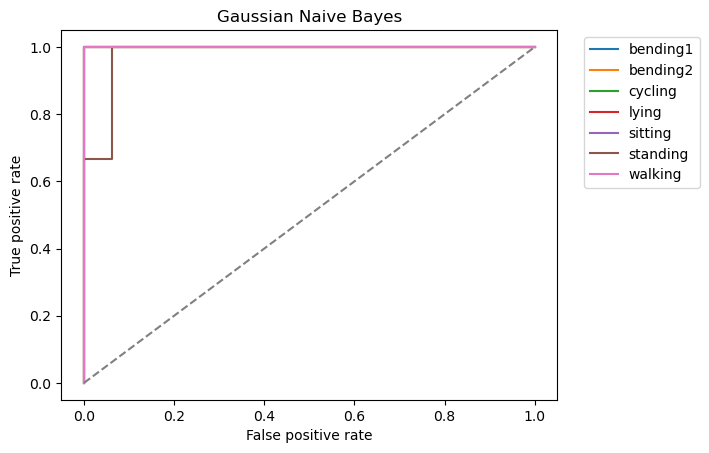

,model,l,cv_accuracy
9,Multinomial,5,0.811275
7,Multinomial,4,0.796569
11,Multinomial,6,0.796569
13,Multinomial,7,0.796569
5,Multinomial,3,0.782680


Multinomial Naive Bayes best l: 5
Cross-validation accuracy: 0.811
Test error: 0.211
Confusion matrix (rows are true activities):


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,1,0,0,0,1,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,2,1,0,0
sitting,0,0,0,0,2,1,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


Macro AUC: 0.966


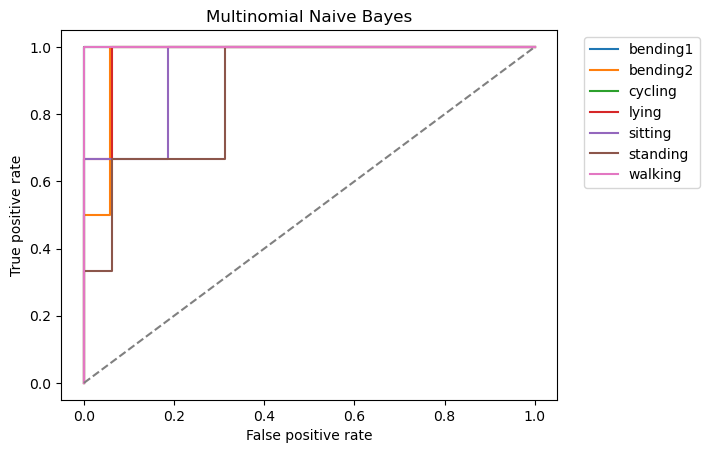

In [12]:
nb_rows = []
for l in range(1, 21):
    data = frames[l].query("split == 'train'").reset_index(drop=True)
    x, names = get_matrix(data, l)
    y = data['activity'].to_numpy()
    models = {'Gaussian': GaussianNB(), 'Multinomial': make_pipeline(MinMaxScaler(clip=True), MultinomialNB())}
    for name, model in models.items():
        scores = cross_val_score(model, x, y, cv=multi_cv, scoring='accuracy')
        nb_rows.append({'model': name, 'l': l, 'cv_accuracy': scores.mean()})
nb_table = pd.DataFrame(nb_rows).sort_values(['cv_accuracy', 'l'], ascending=[False, True])
nb_errors = {}
for name in ['Gaussian', 'Multinomial']:
    results = nb_table[nb_table['model'] == name]
    display(results.head(5))
    best_nb_l = int(results.iloc[0]['l'])
    train = frames[best_nb_l].query("split == 'train'")
    test = frames[best_nb_l].query("split == 'test'")
    x, names = get_matrix(train, best_nb_l)
    x_test, names = get_matrix(test, best_nb_l)
    y = train['activity'].to_numpy()
    y_test = test['activity'].to_numpy()
    if name == 'Gaussian':
        model = GaussianNB()
    else:
        model = make_pipeline(MinMaxScaler(clip=True), MultinomialNB())
    model.fit(x, y)
    pred = model.predict(x_test)
    prob = model.predict_proba(x_test)
    nb_errors[name] = 1 - accuracy_score(y_test, pred)
    print(name, 'Naive Bayes best l:', best_nb_l)
    print('Cross-validation accuracy:', round(float(results.iloc[0]['cv_accuracy']), 3))
    print('Test error:', round(nb_errors[name], 3))
    print('Confusion matrix (rows are true activities):')
    display(pd.DataFrame(confusion_matrix(y_test, pred, labels=activities), index=activities, columns=activities))
    y_binary = label_binarize(y_test, classes=model.classes_)
    print('Macro AUC:', round(roc_auc_score(y_binary, prob, average='macro'), 3))
    for i, activity in enumerate(model.classes_):
        fpr, tpr, _ = roc_curve(y_binary[:, i], prob[:, i])
        plt.plot(fpr, tpr, label=activity)
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.title(name + ' Naive Bayes')
    plt.xlabel('False positive rate')
    plt.ylabel('True positive rate')
    plt.legend(bbox_to_anchor=(1.04, 1), loc='upper left')
    plt.show()

## 2(c)(iii)

In [13]:
errors = {'L1 multinomial logistic regression': 1 - accuracy_score(y_mult_test, mult_pred), 'Gaussian Naive Bayes': nb_errors['Gaussian'], 'Multinomial Naive Bayes': nb_errors['Multinomial']}
for name in errors:
    print(name, 'test error:', round(errors[name], 3))
best_error = min(errors.values())
best_methods = [name for name in errors if errors[name] == best_error]
print('Smallest test error:', ', '.join(best_methods))

L1 multinomial logistic regression test error: 0.158
Gaussian Naive Bayes test error: 0.105
Multinomial Naive Bayes test error: 0.211
Smallest test error: Gaussian Naive Bayes


Gaussian Naive Bayes has the lowest test error: 0.105, compared with 0.158 for L1 multinomial logistic regression and 0.211 for Multinomial Naive Bayes. Each model uses settings chosen with training cross-validation. The test set has only 19 instances, so one instance changes the error by about 0.053.

## 3. ISLR 4.8.3
Here p = 1 and the variance is different for each class. For class k, the QDA score is delta_k(x) = -((x - mu_k)^2 / (2 * sigma_k^2)) - (1/2) * log(sigma_k^2) + log(pi_k) where pi_k is the prior probability of class k. If I expand the square, I get delta_k(x) = -(1 / (2 * sigma_k^2)) * x^2 + (mu_k / sigma_k^2) * x - mu_k^2 / (2 * sigma_k^2) - (1/2) * log(sigma_k^2) + log(pi_k)
The coefficient of x^2 is -1 / (2 * sigma_k^2), and it is different for each class. The Bayes classifier puts x in the class with the largest score. The decision boundary between two classes is where their scores are equal. Because the x^2 coefficients are different, this equation is a quadratic equation in x. So the Bayes classifier is quadratic and not linear.

## 4. ISLR 4.8.7
Let D mean that the company issues a dividend. Let X be last year's percent profit. We know P(D) = 0.8, P(not D) = 0.2, X | D ~ N(10, 6^2) and X | not D ~ N(0, 6^2). We want P(D | X = 4).
By Bayes' rule, P(D | X=4) = f(4 | D) * 0.8 / [f(4 | D) * 0.8 + f(4 | not D) * 0.2]
Both normal densities have the same standard deviation, so the ratio of the two densities is
f(4 | D) / f(4 | not D) = exp(-(4-10)^2 / (2 * 36)) / exp(-(4-0)^2 / (2 * 36)) = exp(-36/72 + 16/72) = exp(-20/72) = 0.757
Then P(D | X=4) = 0.8 * 0.757 / (0.8 * 0.757 + 0.2) = 0.752
The probability that the company issues a dividend is about 75.2%.